Separate features and target

In [1]:
import pandas as pd

df = pd.read_csv("../dataset/raw/post natal data.csv")

df = df.drop(columns=["Timestamp"])

TARGET_COLUMN = "Feeling anxious"

# Keep only records with a known binary target
df = df[df[TARGET_COLUMN].isin(["Yes", "No"])].copy()

# Binary target
y = df[TARGET_COLUMN].map({
    "No": 0,
    "Yes": 1
})

# Input features
X = df.drop(columns=[TARGET_COLUMN])

print("Features:", X.shape)
print("Target:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features: (1503, 9)
Target: (1503,)

Target distribution:
Feeling anxious
1    980
0    523
Name: count, dtype: int64


Split training and testing data

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1202
Testing records: 301


Create preprocessing pipeline

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_features),
    ("numerical", numerical_pipeline, numerical_features)
])

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


C:\Users\user\AppData\Local\Temp\ipykernel_20008\1934174622.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


Train the five machine learning algorithms

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42
    ),

    "SVM": SVC(
        probability=True,
        class_weight="balanced",
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        eval_metric="logloss",
        random_state=42
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        class_weight="balanced",
        verbosity=-1,
        random_state=42
    )
}

print("Five ML models defined!")

Five ML models defined!


Train and compare the models

In [5]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)

print(results_df.round(4))

c:\Users\user\Desktop\Care AI\PPD_Risk_Prediction\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression    0.8040     0.8663  0.8265    0.8460   0.8969
1        Random Forest    0.9867     1.0000  0.9796    0.9897   0.9998
2                  SVM    0.9502     0.9594  0.9643    0.9618   0.9879
3              XGBoost    0.9369     0.9492  0.9541    0.9517   0.9778
4             LightGBM    0.9767     1.0000  0.9643    0.9818   1.0000


Visualize model comparison

In [7]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


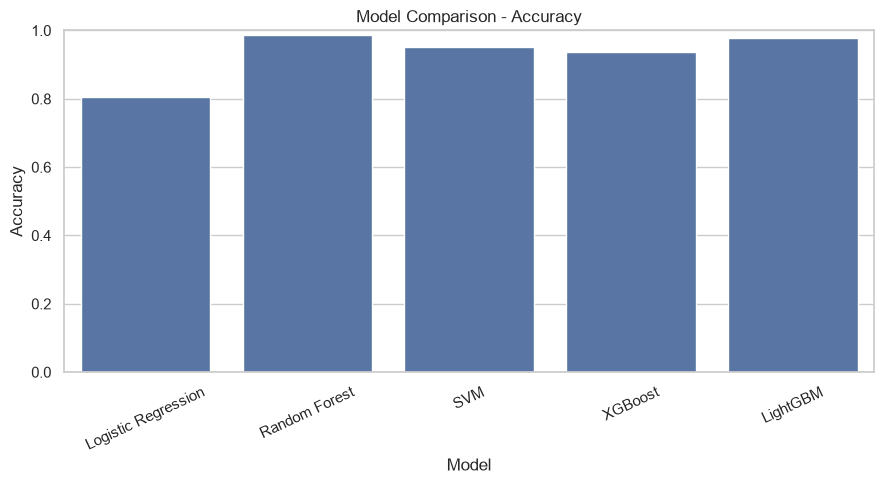

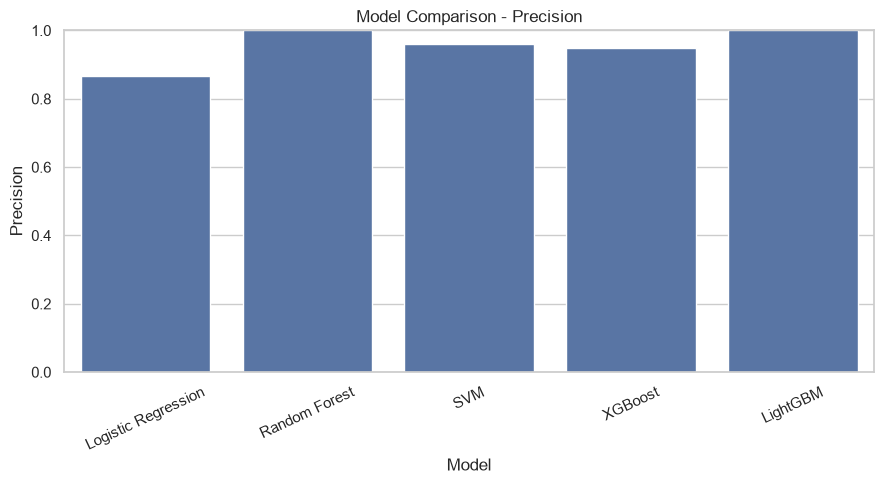

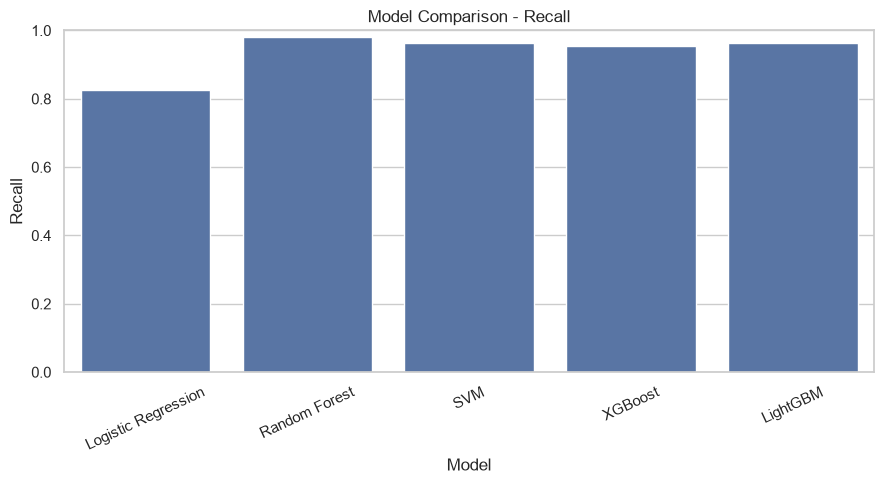

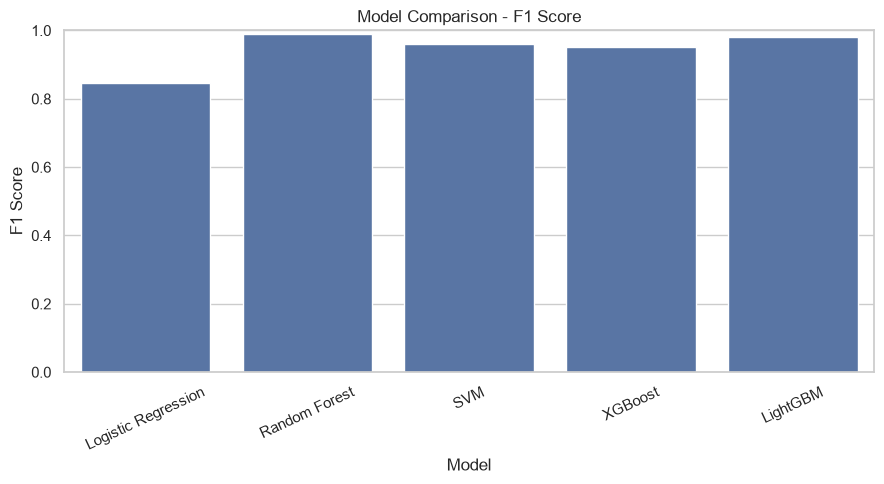

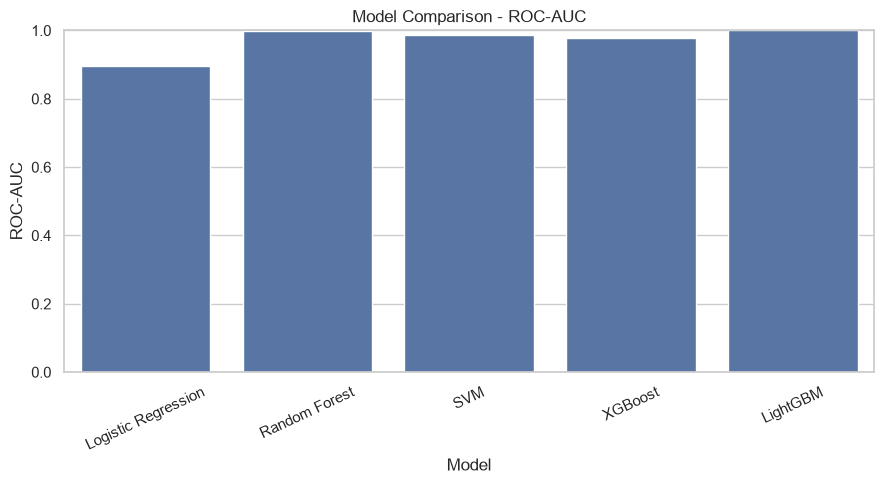

In [8]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

for metric in metrics:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xticks(rotation=25)
    plt.ylim(0, 1)
    plt.tight_layout()

    plt.show()

Generate classification reports

In [9]:
for name, pipeline in trained_models.items():

    print("\n==============================")
    print("MODEL:", name)
    print("==============================")

    predictions = pipeline.predict(X_test)

    print(
        classification_report(
            y_test,
            predictions,
            zero_division=0
        )
    )


MODEL: Logistic Regression
              precision    recall  f1-score   support

           0       0.70      0.76      0.73       105
           1       0.87      0.83      0.85       196

    accuracy                           0.80       301
   macro avg       0.78      0.79      0.79       301
weighted avg       0.81      0.80      0.81       301


MODEL: Random Forest
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       105
           1       1.00      0.98      0.99       196

    accuracy                           0.99       301
   macro avg       0.98      0.99      0.99       301
weighted avg       0.99      0.99      0.99       301


MODEL: SVM
              precision    recall  f1-score   support

           0       0.93      0.92      0.93       105
           1       0.96      0.96      0.96       196

    accuracy                           0.95       301
   macro avg       0.95      0.94      0.95       301
weighted avg

#### Class imbalance handling

Visualize class distribution

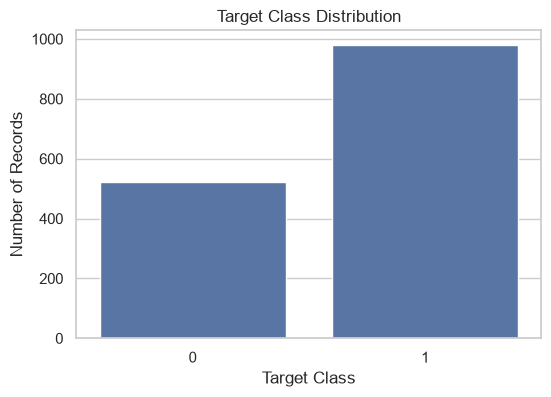

In [10]:
plt.figure(figsize=(6, 4))

sns.countplot(x=y)

plt.title("Target Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Records")

plt.show()

Check imbalance ratio

In [11]:
print(y.value_counts())

print("\nClass percentages:")
print(y.value_counts(normalize=True) * 100)

Feeling anxious
1    980
0    523
Name: count, dtype: int64

Class percentages:
Feeling anxious
1    65.202927
0    34.797073
Name: proportion, dtype: float64
